In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

%load_ext autoreload
%autoreload 2

from src import config as C
from src import data_preprocessing as dp

print("Dataset:", C.DATASET_DIR)

Dataset: D:\ppe-safety\data\raw\construction-safety


In [2]:
names = dp.load_class_names()
counts = dp.count_objects_per_class(names)
counts

,train,valid,test,total
Person,808,166,174,1148
Safety Cone,464,44,92,600
NO-Safety Vest,386,106,90,582
Hardhat,385,79,110,574
NO-Mask,338,74,79,491
Safety Vest,322,41,61,424
NO-Hardhat,292,69,41,402
Gloves,231,25,40,296
Mask,153,21,28,202
Excavator,145,12,9,166


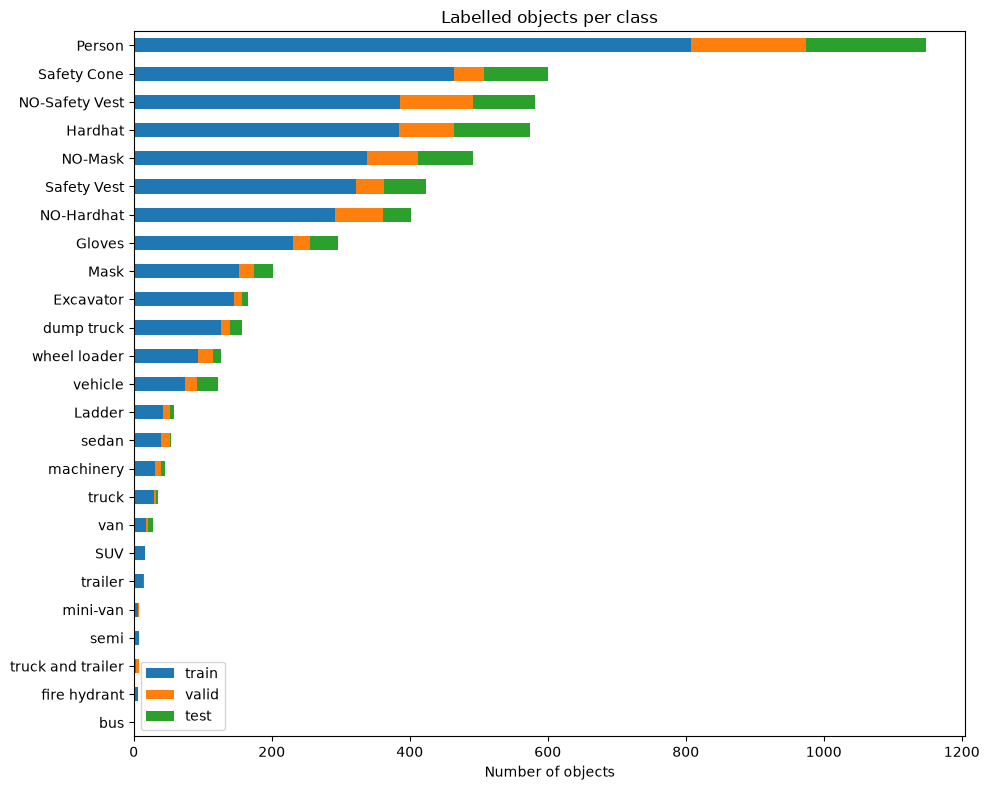

In [3]:
import matplotlib.pyplot as plt

ax = counts[C.SPLITS].plot.barh(stacked=True, figsize=(10, 8))
ax.invert_yaxis()
ax.set_title("Labelled objects per class")
ax.set_xlabel("Number of objects")
plt.tight_layout()
plt.savefig(C.FIGURES_DIR / "class_distribution.png", dpi=150)
plt.show()

## Class mapping: before and after

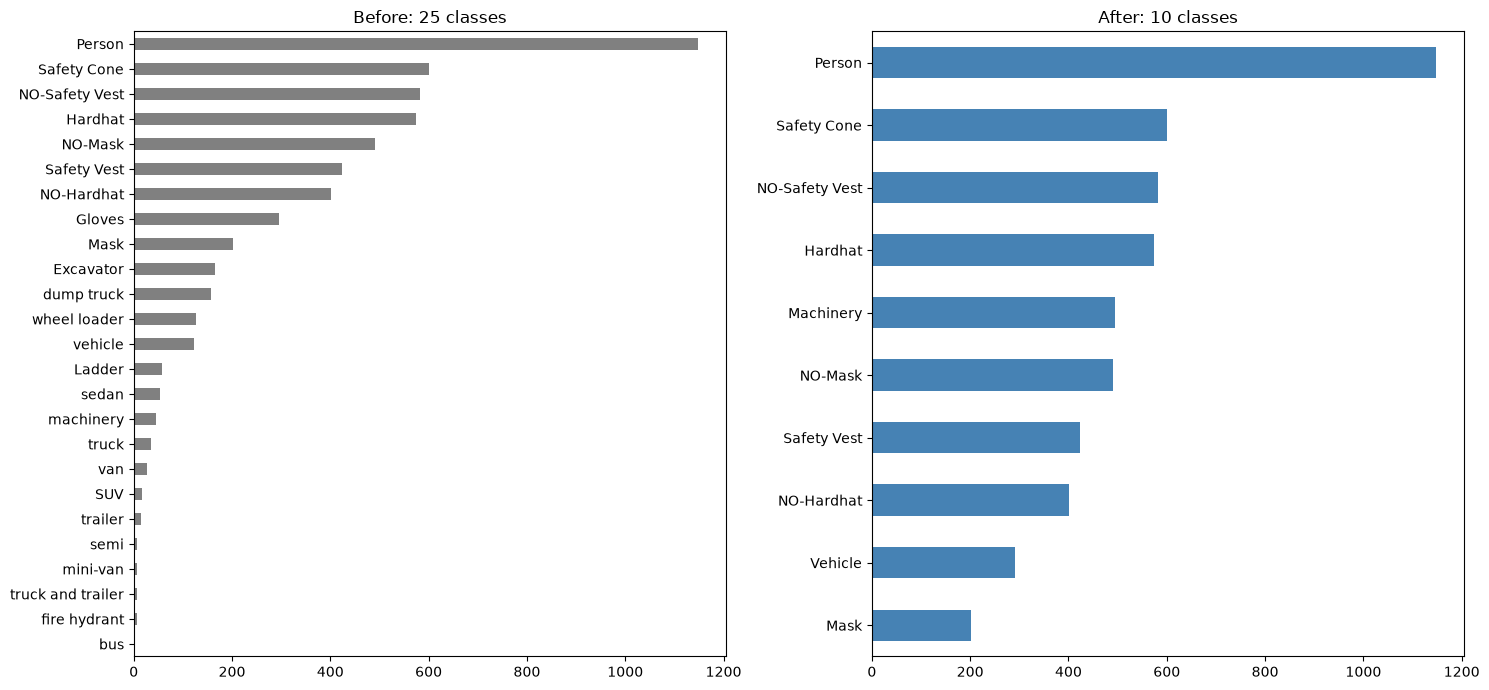

Imbalance before: 1148x
Imbalance after : 5.7x


In [4]:
import pandas as pd
from src import feature_engineering as fe

before = pd.read_csv(C.METRICS_DIR / "class_distribution_raw.csv", index_col=0)
after  = pd.read_csv(C.METRICS_DIR / "class_distribution_final.csv", index_col=0)

fig, axes = plt.subplots(1, 2, figsize=(15, 7))
before["total"].sort_values().plot.barh(ax=axes[0], color="gray", title="Before: 25 classes")
after["total"].sort_values().plot.barh(ax=axes[1], color="steelblue", title="After: 10 classes")
plt.tight_layout()
plt.savefig(C.FIGURES_DIR / "class_mapping_before_after.png", dpi=150)
plt.show()

print(f"Imbalance before: {before['total'].max() / before['total'].min():.0f}x")
print(f"Imbalance after : {after['total'].max() / after['total'].min():.1f}x")

## Image inspection (Phase 3.1)

In [5]:
img_df = dp.inspect_images()
img_df.to_csv(C.METRICS_DIR / "image_inspection.csv", index=False)

print("Total images     :", len(img_df))
print("Unreadable       :", (~img_df["readable"]).sum())
print("Missing label    :", (~img_df["has_label"]).sum())
print("Images with 0 box:", (img_df["n_boxes"] == 0).sum())
img_df.groupby("split")[["width", "height", "brightness", "n_boxes"]].describe().round(0).T

Total images     : 717
Unreadable       : 0
Missing label    : 0
Images with 0 box: 53


split               test   train   valid
width      count    65.0   573.0    79.0
           mean   1026.0  1038.0  1007.0
           std     711.0   512.0   658.0
           min     183.0   175.0   188.0
           25%     500.0   639.0   450.0
           50%    1080.0  1080.0  1024.0
           75%    1280.0  1280.0  1280.0
           max    4793.0  4000.0  4000.0
height     count    65.0   573.0    79.0
           mean    722.0   827.0   772.0
           std     611.0   611.0   732.0
           min     256.0   183.0   225.0
           25%     335.0   480.0   368.0
           50%     720.0   720.0   720.0
           75%     720.0   920.0   720.0
           max    3840.0  4032.0  3840.0
brightness count    65.0   573.0    79.0
           mean    127.0   123.0   125.0
           std      32.0    27.0    29.0
           min      49.0     0.0    52.0
           25%     106.0   109.0   105.0
           50%     126.0   124.0   122.0
           75%     147.0   138.0   147.0
           max     216.0   221.0   225.0
n_boxes    count    65.0   573.0    79.0
           mean     10.0     7.0     6.0
           std      15.0    10.0     8.0
           min       0.0     0.0     0.0
           25%       3.0     2.0     2.0
           50%       5.0     4.0     4.0
           75%      10.0     7.0     7.0
           max      84.0    98.0    58.0

## Annotation validation (Phase 3.3)

In [6]:
issues = dp.validate_labels(len(fe.TARGET_CLASSES))
issues.to_csv(C.METRICS_DIR / "annotation_issues.csv", index=False)
print("Issues found:", len(issues))
issues["problem"].value_counts() if len(issues) else "All labels valid"

Issues found: 0


'All labels valid'

## 20 random training images (Phase 3.4)

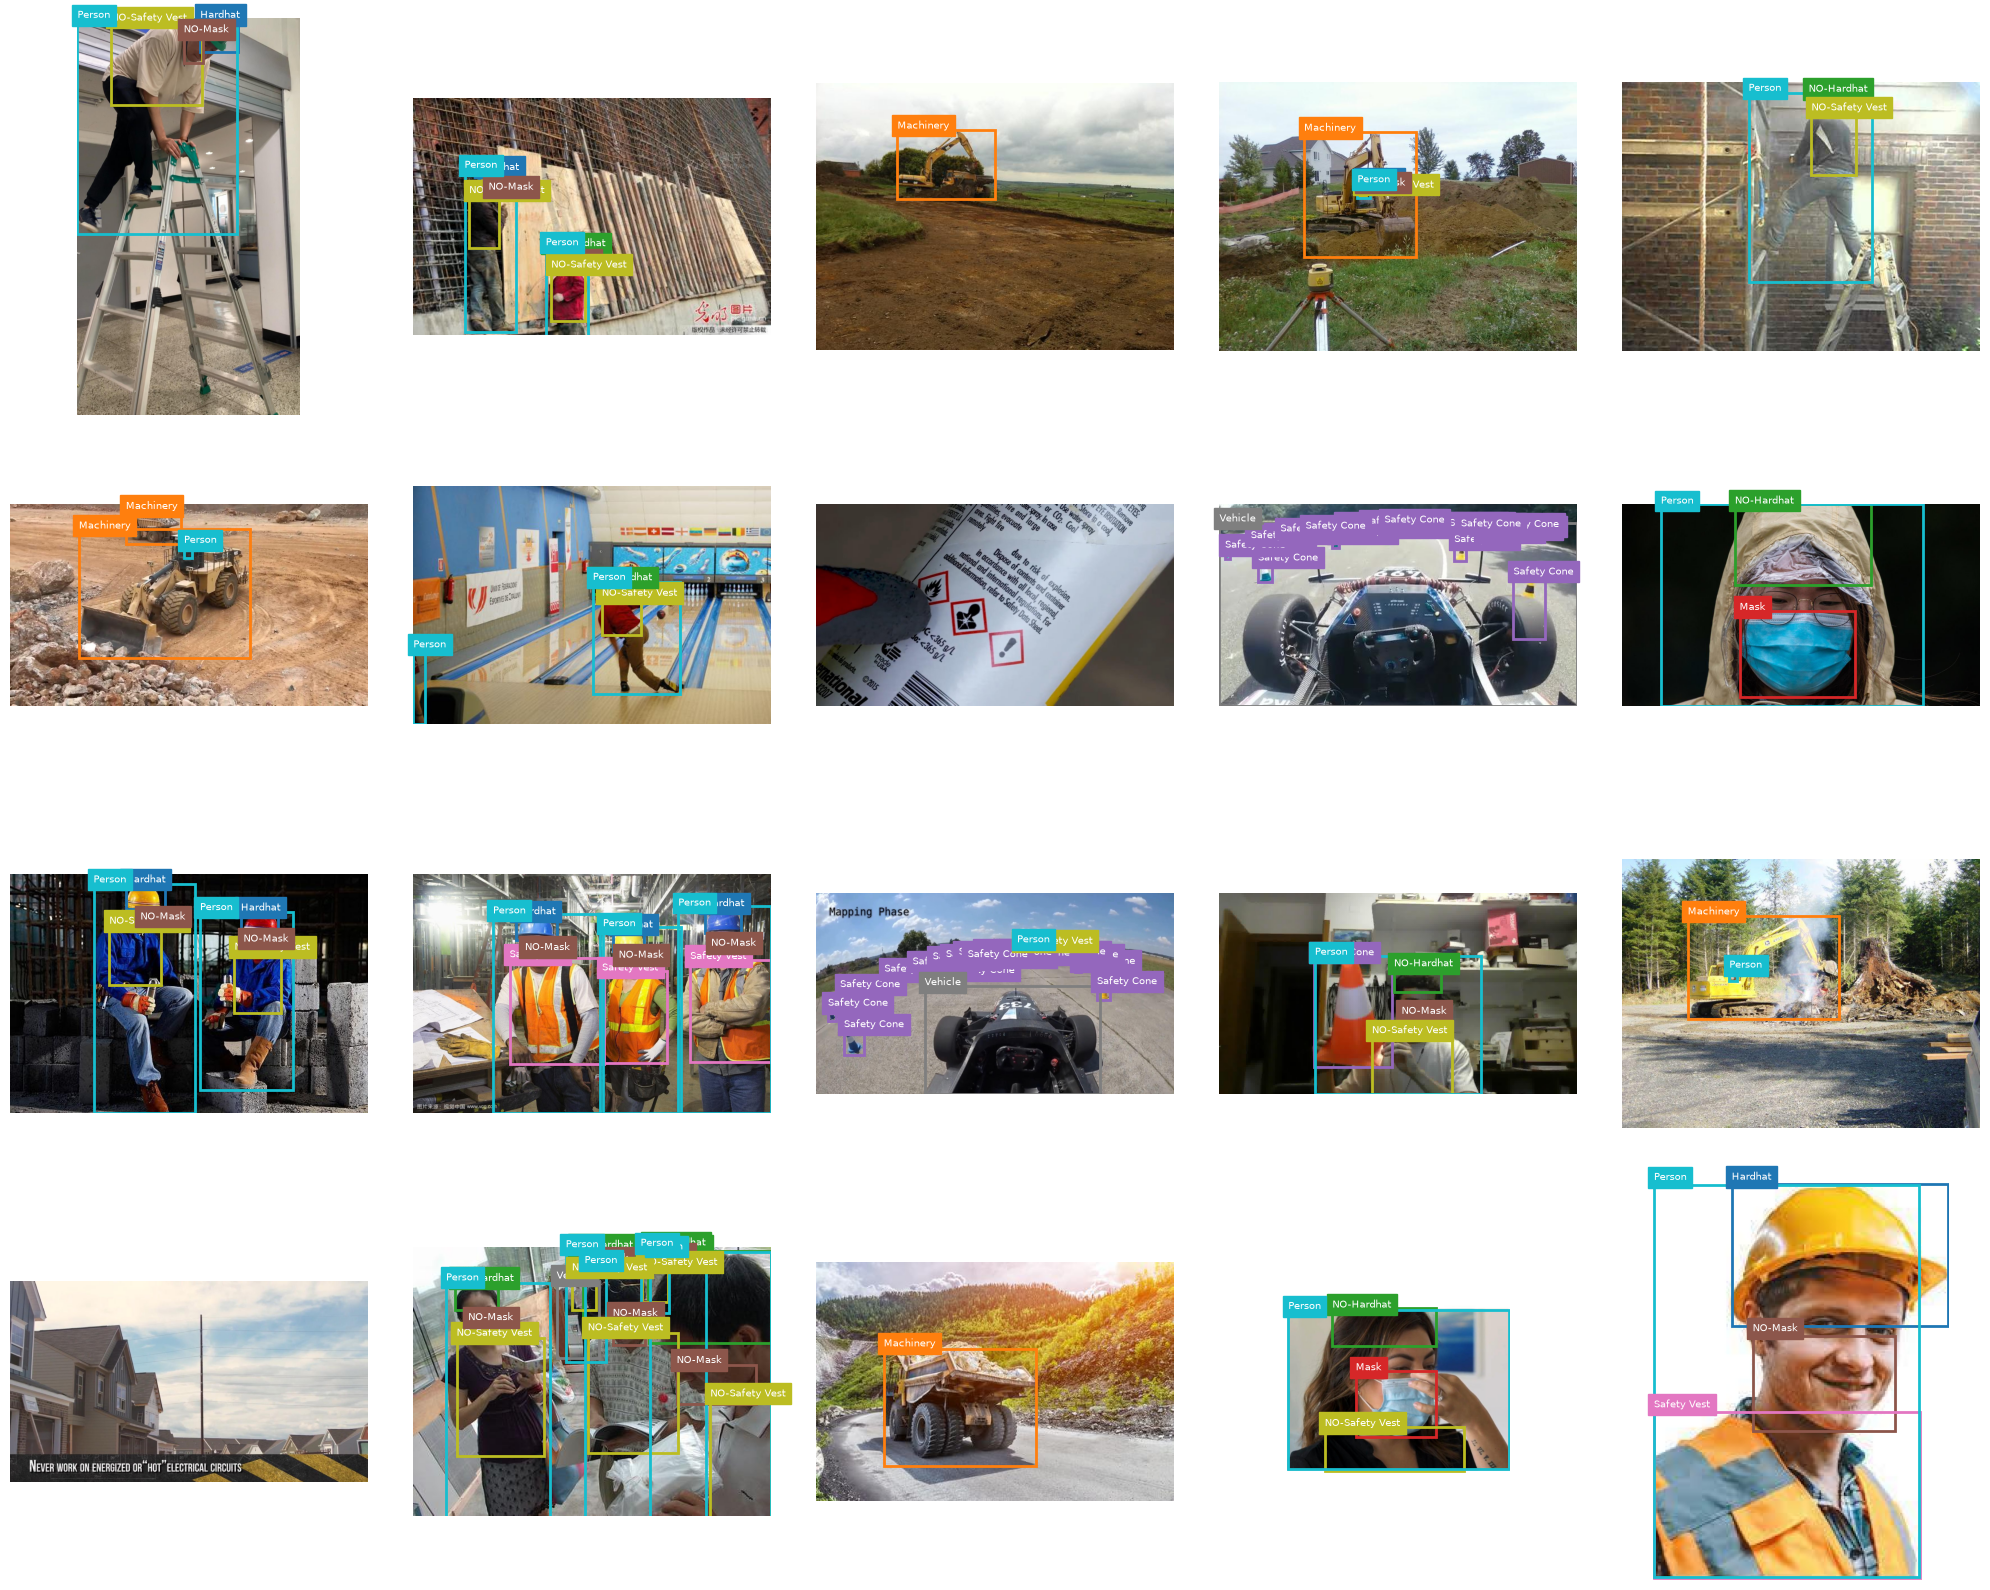

In [7]:
import random
import cv2

names = fe.TARGET_CLASSES
colors = plt.cm.tab10.colors

train_imgs = sorted((C.PROCESSED_DIR / "train" / "images").glob("*"))
sample = random.Random(C.SEED).sample(train_imgs, 20)

fig, axes = plt.subplots(4, 5, figsize=(20, 16))
for ax, img_path in zip(axes.flat, sample):
    img = cv2.cvtColor(cv2.imread(str(img_path)), cv2.COLOR_BGR2RGB)
    H, W = img.shape[:2]
    label = C.PROCESSED_DIR / "train" / "labels" / f"{img_path.stem}.txt"
    for cid, x, y, w, h in dp.read_boxes(label):
        x1, y1 = (x - w/2) * W, (y - h/2) * H
        ax.add_patch(plt.Rectangle((x1, y1), w * W, h * H, fill=False,
                                   edgecolor=colors[cid], linewidth=2))
        ax.text(x1, y1 - 3, names[cid], color="white", fontsize=7,
                backgroundcolor=colors[cid])
    ax.imshow(img)
    ax.axis("off")
plt.tight_layout()
plt.savefig(C.FIGURES_DIR / "sample_annotations_20.png", dpi=110)
plt.show()

## Observations
1. 53 images have 0 boxes (7.4%). These are mostly images that only contained Gloves, Ladder or fire hydrant, which I dropped, plus pure background images like the shop picture in this grid. Keep them. YOLO uses them as “background” examples that teach it what not to detect, which reduces false alarms. Around 5–10% background images is a healthy amount.

2. Image sizes vary a lot (175 px to 4793 px). YOLO resizes everything to 640 px. Small images get upscaled and blurry, and in very large images, distant hard hats shrink to just a few pixels. Expect small, distant PPE to be the hardest case. Note this now, because it will help explain this results in the error analysis.

3. Crowded scenes: the median is 4 boxes per image, but some images have up to 98. These dense scenes are hard to detect accurately.

4. Brightness min = 0 in train. At least one image is completely black. Check it (code below).

5. Some images in this grid look odd for the domain. The race-car image (“Mapping Phase”) is labelled with Safety Cones and Vehicle, the excavator by the sea has no workers, and the shop image has no boxes. This is normal for web-scraped datasets. Mention it as a limitation: the data isn’t all from real construction sites.

6. NO-Mask is very common (491 vs 202 Mask). Most site workers don’t wear masks, so the model will flag NO-Mask often. In this app, it makes sense to treat NO-Mask as a lower-priority warning than NO-Hardhat or NO-Safety Vest. 


     split                                               file  brightness  \
433  train  youtube-10_jpg.rf.534130de2cfdd8e9e772bee60bea...   23.548669   
486  train  youtube-391_jpg.rf.31329fd91be63db7008baad5181...    0.023563   

     n_boxes  
433        0  
486        0  


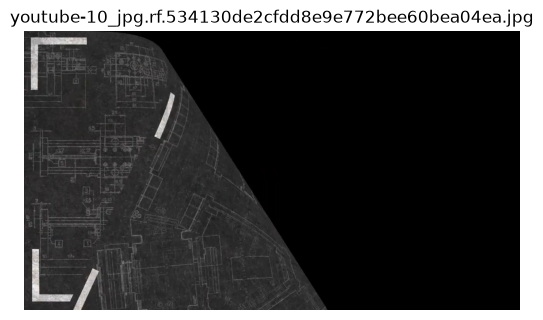

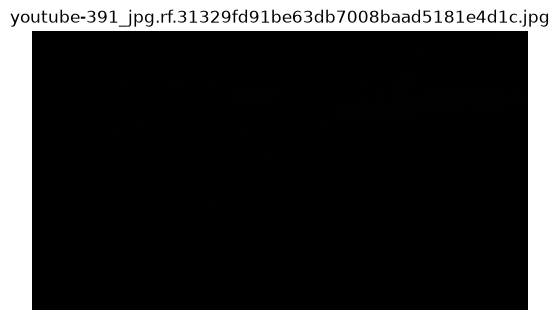

In [8]:
dark = img_df[img_df["brightness"] < 30]
print(dark[["split", "file", "brightness", "n_boxes"]])

for _, r in dark.iterrows():
    img = cv2.imread(str(C.PROCESSED_DIR / r["split"] / "images" / r["file"]))
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); plt.title(r["file"]); plt.axis("off"); plt.show()

## Duplicate and leakage check

In [9]:
leaks = dp.find_cross_split_duplicates()
leaks.to_csv(C.METRICS_DIR / "split_leakage.csv", index=False)
print("Possible leaks between splits:", len(leaks))
leaks.head(20)

Possible leaks between splits: 0


,type,files,splits


In [10]:
for files in leaks["files"].head(3):
    a, b = [f.strip() for f in files.split("|")] if "|" in files else files.split(", ")[:2]
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    for ax, f in zip(axes, [a, b]):
        path = next(C.PROCESSED_DIR.glob(f"*/images/{f}"))
        ax.imshow(cv2.cvtColor(cv2.imread(str(path)), cv2.COLOR_BGR2RGB)); ax.set_title(f[:30], fontsize=8); ax.axis("off")
    plt.show()

## After the leakage fix

In [11]:
leaks_after = dp.find_cross_split_duplicates()
print("Leaks after fix:", len(leaks_after))

for split in C.SPLITS:
    n = len(list((C.PROCESSED_DIR / split / "images").glob("*")))
    print(f"{split:5s} {n:4d}  ({100 * n / 717:.1f}%)")

Leaks after fix: 0
train  573  (79.9%)
valid   79  (11.0%)
test    65  (9.1%)


## Model comparison: YOLO11n vs YOLO26n

In [12]:
import json
import time
from ultralytics import YOLO

models = {"YOLO11n": "exp_a_yolo11n", "YOLO26n": "exp_b_yolo26n"}
violation = ["NO-Hardhat", "NO-Safety Vest"]
test_imgs = sorted((C.PROCESSED_DIR / "valid" / "images").glob("*"))[:40]

rows = []
for label, name in models.items():
    overall = json.load(open(C.METRICS_DIR / f"{name}_val.json"))
    pc = pd.read_csv(C.METRICS_DIR / f"{name}_val_per_class.csv").set_index("class")

    # CPU speed on the same 40 images (after 5 warm-up runs)
    m = YOLO(str(C.MODELS_DIR / f"{name}.pt"))
    for p in test_imgs[:5]:
        m.predict(str(p), verbose=False)
    t0 = time.perf_counter()
    for p in test_imgs:
        m.predict(str(p), verbose=False)
    ms = 1000 * (time.perf_counter() - t0) / len(test_imgs)

    rows.append({"model": label, "mAP50": overall["mAP50"], "mAP50-95": overall["mAP50_95"],
                 "precision": overall["precision"], "recall": overall["recall"],
                 "violation recall": pc.loc[violation, "recall"].mean(),
                 "ms/image (CPU)": ms, "FPS": 1000 / ms})

comparison = pd.DataFrame(rows).set_index("model").round(3)
comparison.to_csv(C.METRICS_DIR / "model_comparison.csv")
comparison

,mAP50,mAP50-95,precision,recall,violation recall,ms/image (CPU),FPS
model,,,,,,,
YOLO11n,0.606,0.364,0.740,0.542,0.476,80.496,12.423
YOLO26n,0.647,0.408,0.738,0.604,0.501,67.237,14.873


In [13]:
import json
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from ultralytics import YOLO

from src import config as C
from src import data_preprocessing as dp
from src import feature_engineering as fe

BLUE, ORANGE, AQUA, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#8a8a85"
MODEL_COLORS = {"YOLO11n": BLUE, "YOLO26n": ORANGE}
SPLIT_COLORS = {"train": BLUE, "valid": ORANGE, "test": AQUA}
RUNS = C.MODELS_DIR / "runs"
MODELS = {"YOLO11n": "exp_a_yolo11n", "YOLO26n": "exp_b_yolo26n"}
FINAL = "exp_b_yolo26n"
VIOLATION = ["NO-Hardhat", "NO-Safety Vest"]

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e6e3", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.edgecolor": "#bdbdb8",
    "axes.titleweight": "bold", "axes.titlesize": 12, "legend.frameon": False,
})

def save(fig, name):
    fig.tight_layout()
    fig.savefig(C.FIGURES_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

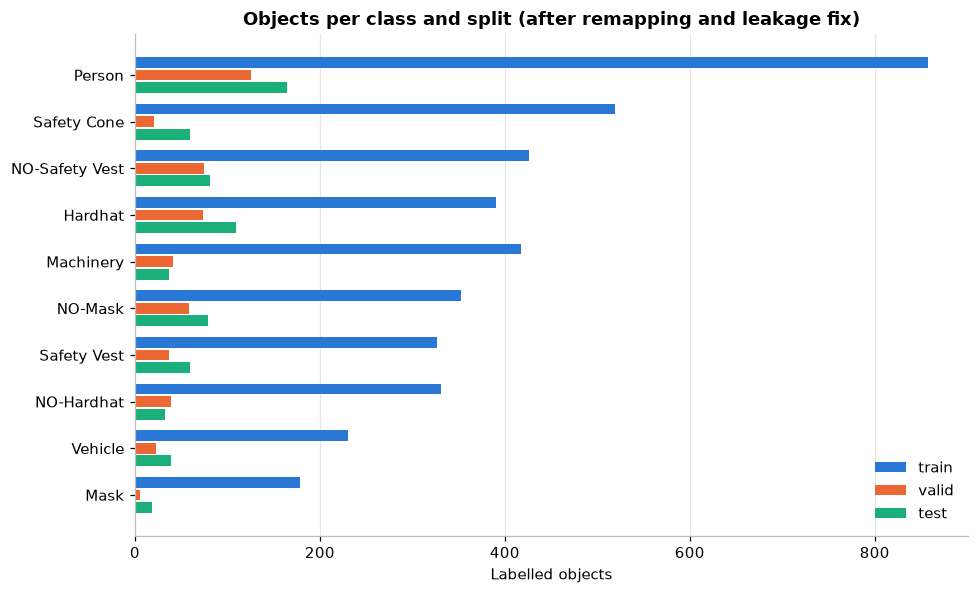

In [14]:
dist = dp.count_objects_per_class(fe.TARGET_CLASSES, C.PROCESSED_DIR).sort_values("total")

fig, ax = plt.subplots(figsize=(9, 5.5))
y, h = np.arange(len(dist)), 0.27
for i, split in enumerate(C.SPLITS):
    ax.barh(y + (1 - i) * h, dist[split], height=h - 0.04, color=SPLIT_COLORS[split], label=split)
ax.set_yticks(y, dist.index)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Labelled objects")
ax.set_title("Objects per class and split (after remapping and leakage fix)")
ax.legend(loc="lower right")
save(fig, "01_objects_per_class_split")

D:\temp\ipykernel_9864\1834838072.py:9: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot([boxes.loc[boxes["class"] == c, "size"] for c in order], vert=False,


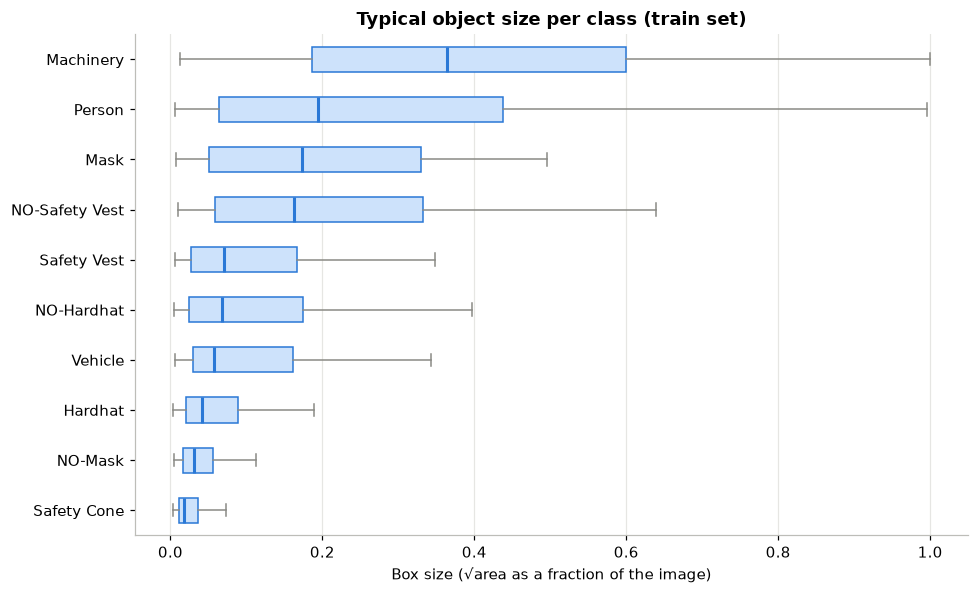

In [15]:
rows = []
for lbl in (C.PROCESSED_DIR / "train" / "labels").glob("*.txt"):
    for cid, x, y, w, h in dp.read_boxes(lbl):
        rows.append({"class": fe.TARGET_CLASSES[cid], "size": np.sqrt(w * h)})
boxes = pd.DataFrame(rows)
order = boxes.groupby("class")["size"].median().sort_values().index

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.boxplot([boxes.loc[boxes["class"] == c, "size"] for c in order], vert=False,
           showfliers=False, patch_artist=True,
           boxprops=dict(facecolor="#cde2fb", edgecolor=BLUE),
           medianprops=dict(color=BLUE, linewidth=2),
           whiskerprops=dict(color=GREY), capprops=dict(color=GREY))
ax.set_yticks(range(1, len(order) + 1), order)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Box size (√area as a fraction of the image)")
ax.set_title("Typical object size per class (train set)")
save(fig, "02_box_size_per_class")

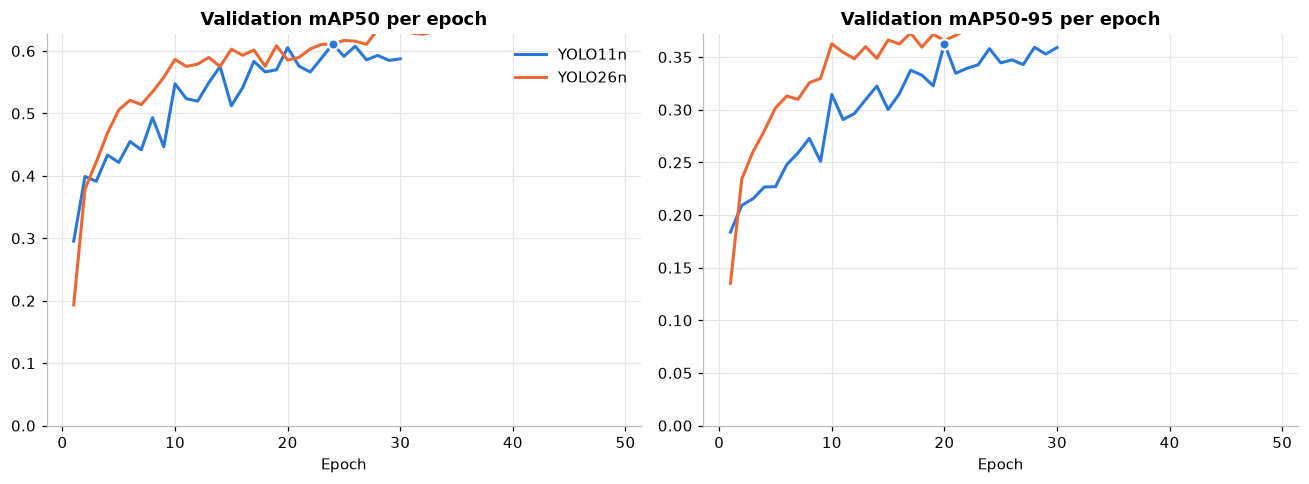

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharex=True)
cols = {"metrics/mAP50(B)": "mAP50", "metrics/mAP50-95(B)": "mAP50-95"}
for label, name in MODELS.items():
    r = pd.read_csv(RUNS / name / "results.csv")
    r.columns = r.columns.str.strip()
    for ax, (col, title) in zip(axes, cols.items()):
        ax.plot(r["epoch"], r[col], color=MODEL_COLORS[label], linewidth=2, label=label)
        best = r[col].idxmax()
        ax.scatter(r.loc[best, "epoch"], r.loc[best, col], s=45, color=MODEL_COLORS[label],
                   edgecolor="white", linewidth=1.5, zorder=3)
        ax.set_title(f"Validation {title} per epoch")
        ax.set_xlabel("Epoch")
        ax.set_ylim(0, None)
axes[0].legend()
save(fig, "03_training_curves")

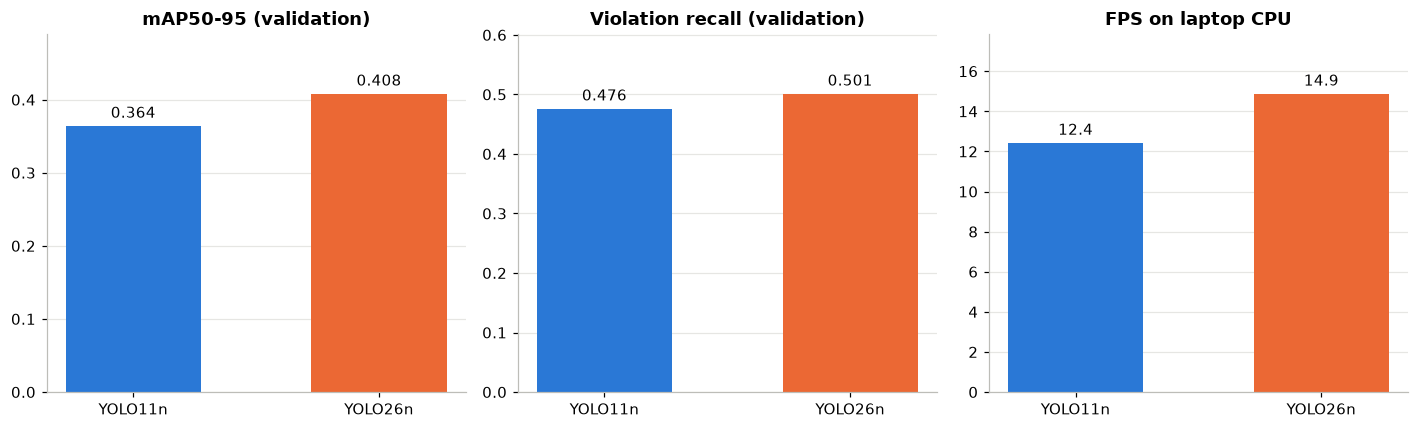

In [17]:
comp = pd.read_csv(C.METRICS_DIR / "model_comparison.csv", index_col=0)

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, col, title in zip(axes, ["mAP50-95", "violation recall", "FPS"],
                          ["mAP50-95 (validation)", "Violation recall (validation)", "FPS on laptop CPU"]):
    bars = ax.bar(comp.index, comp[col], color=[MODEL_COLORS[m] for m in comp.index], width=0.55)
    ax.bar_label(bars, fmt="%.3f" if col != "FPS" else "%.1f", padding=3, fontsize=10)
    ax.set_title(title)
    ax.grid(axis="x", visible=False)
    ax.set_ylim(0, comp[col].max() * 1.2)
save(fig, "04_model_comparison")

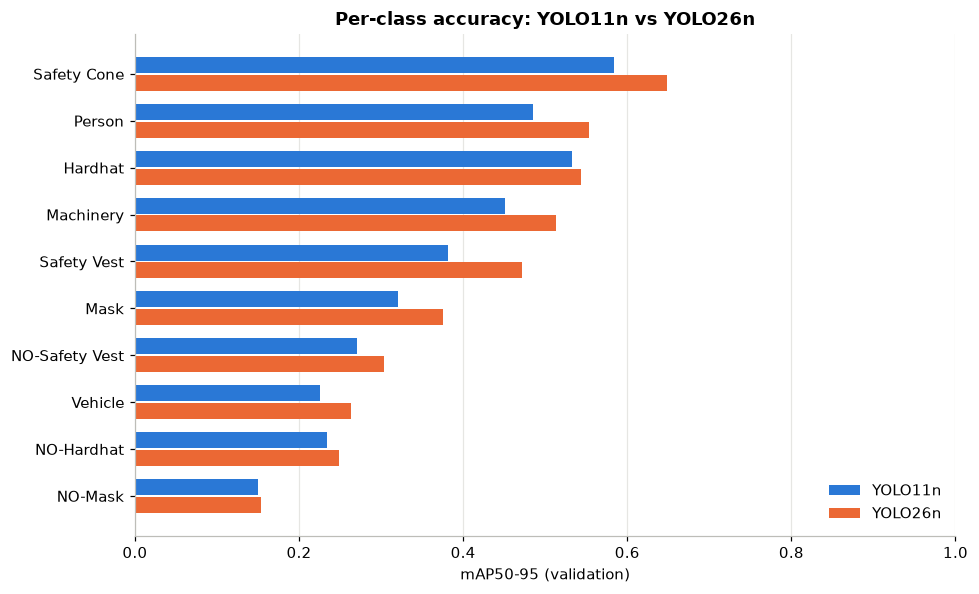

In [18]:
pc = pd.DataFrame({lab: pd.read_csv(C.METRICS_DIR / f"{n}_val_per_class.csv").set_index("class")["mAP50_95"]
                   for lab, n in MODELS.items()}).sort_values("YOLO26n")

fig, ax = plt.subplots(figsize=(9, 5.5))
y, h = np.arange(len(pc)), 0.38
for i, lab in enumerate(MODELS):
    ax.barh(y + (0.5 - i) * h, pc[lab], height=h - 0.04, color=MODEL_COLORS[lab], label=lab)
ax.set_yticks(y, pc.index)
ax.grid(axis="y", visible=False)
ax.set_xlim(0, 1)
ax.set_xlabel("mAP50-95 (validation)")
ax.set_title("Per-class accuracy: YOLO11n vs YOLO26n")
ax.legend(loc="lower right")
save(fig, "05_per_class_comparison")

In [19]:
def box_iou(a, b):
    """IoU of one box a (x1,y1,x2,y2) with many boxes b (n,4)."""
    x1, y1 = np.maximum(a[0], b[:, 0]), np.maximum(a[1], b[:, 1])
    x2, y2 = np.minimum(a[2], b[:, 2]), np.minimum(a[3], b[:, 3])
    inter = np.clip(x2 - x1, 0, None) * np.clip(y2 - y1, 0, None)
    area_a = (a[2] - a[0]) * (a[3] - a[1])
    area_b = (b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1])
    return inter / (area_a + area_b - inter + 1e-9)


def match_split(model, split, iou_thr=0.5):
    """Predict on a split at low confidence and match each prediction to a label.
    preds: one row per prediction (class, conf, tp)
    gts:   one row per labelled object (class, matched_conf, size in px, box)"""
    preds, gts = [], []
    for img_path in sorted((C.PROCESSED_DIR / split / "images").glob("*")):
        res = model.predict(str(img_path), conf=0.05, verbose=False)[0]
        H, W = res.orig_shape
        scale = 640 / max(H, W)                       # size as the model sees it
        label = C.PROCESSED_DIR / split / "labels" / f"{img_path.stem}.txt"
        gt = [(cid, np.array([(x - w/2) * W, (y - h/2) * H, (x + w/2) * W, (y + h/2) * H]))
              for cid, x, y, w, h in dp.read_boxes(label)]
        gt_conf = [0.0] * len(gt)

        p_xyxy = res.boxes.xyxy.cpu().numpy()
        p_cls = res.boxes.cls.cpu().numpy().astype(int)
        p_conf = res.boxes.conf.cpu().numpy()
        for i in np.argsort(-p_conf):                 # most confident first
            cand = [j for j, (cid, _) in enumerate(gt) if cid == p_cls[i] and gt_conf[j] == 0]
            tp = False
            if cand:
                ious = box_iou(p_xyxy[i], np.stack([gt[j][1] for j in cand]))
                k = ious.argmax()
                if ious[k] >= iou_thr:
                    gt_conf[cand[k]] = p_conf[i]
                    tp = True
            preds.append({"image": img_path.name, "class": model.names[p_cls[i]],
                          "conf": p_conf[i], "tp": tp})

        for (cid, b), mc in zip(gt, gt_conf):
            gts.append({"image": img_path.name, "class": model.names[cid], "matched_conf": mc,
                        "side_px": np.sqrt((b[2] - b[0]) * (b[3] - b[1])) * scale, "box": b})
    return pd.DataFrame(preds), pd.DataFrame(gts)


final_model = YOLO(str(C.MODELS_DIR / f"{FINAL}.pt"))
val_preds, val_gts = match_split(final_model, "valid")
test_preds, test_gts = match_split(final_model, "test")
print(f"valid: {len(val_gts)} objects | test: {len(test_gts)} objects")

valid: 500 objects | test: 679 objects


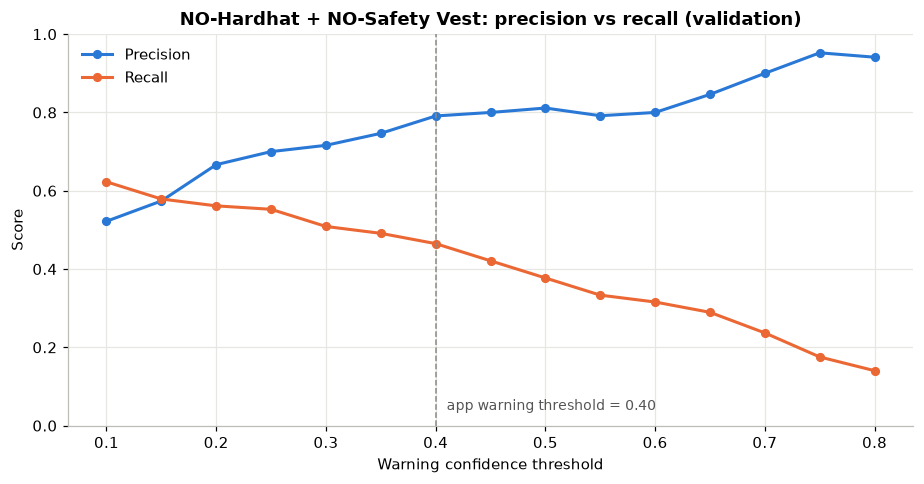

,threshold,precision,recall
0,0.10,0.522,0.623
1,0.15,0.574,0.579
2,0.20,0.667,0.561
3,0.25,0.700,0.553
4,0.30,0.716,0.509
5,0.35,0.747,0.491
6,0.40,0.791,0.465
7,0.45,0.800,0.421
8,0.50,0.811,0.377
9,0.55,0.792,0.333


In [20]:
ths = np.round(np.arange(0.10, 0.81, 0.05), 2)
g = val_gts[val_gts["class"].isin(VIOLATION)]
sweep = []
for t in ths:
    p = val_preds[val_preds["class"].isin(VIOLATION) & (val_preds["conf"] >= t)]
    sweep.append({"threshold": t,
                  "precision": p["tp"].mean() if len(p) else np.nan,
                  "recall": (g["matched_conf"] >= t).mean()})
sweep = pd.DataFrame(sweep)

fig, ax = plt.subplots(figsize=(8.5, 4.5))
ax.plot(sweep["threshold"], sweep["precision"], color=BLUE, lw=2, marker="o", ms=5, label="Precision")
ax.plot(sweep["threshold"], sweep["recall"], color=ORANGE, lw=2, marker="o", ms=5, label="Recall")
ax.axvline(0.40, color=GREY, ls="--", lw=1)
ax.text(0.41, 0.04, "app warning threshold = 0.40", color="#555", fontsize=9)
ax.set_ylim(0, 1)
ax.set_xlabel("Warning confidence threshold")
ax.set_ylabel("Score")
ax.set_title("NO-Hardhat + NO-Safety Vest: precision vs recall (validation)")
ax.legend()
save(fig, "06_threshold_tradeoff")
sweep.round(3)

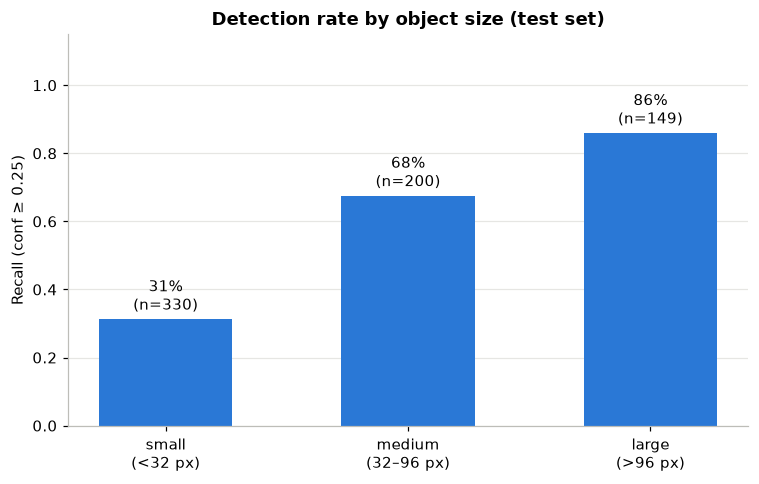

In [21]:
bins, labels = [0, 32, 96, np.inf], ["small\n(<32 px)", "medium\n(32–96 px)", "large\n(>96 px)"]
test_gts["size"] = pd.cut(test_gts["side_px"], bins, labels=labels)
test_gts["found"] = test_gts["matched_conf"] >= 0.25
by_size = test_gts.groupby("size", observed=False).agg(recall=("found", "mean"), n=("found", "size"))

fig, ax = plt.subplots(figsize=(7, 4.5))
bars = ax.bar(by_size.index.astype(str), by_size["recall"], color=BLUE, width=0.55)
ax.bar_label(bars, labels=[f"{r:.0%}\n(n={n})" for r, n in zip(by_size["recall"], by_size["n"])],
             padding=3, fontsize=10)
ax.set_ylim(0, 1.15)
ax.grid(axis="x", visible=False)
ax.set_ylabel("Recall (conf ≥ 0.25)")
ax.set_title("Detection rate by object size (test set)")
save(fig, "07_recall_by_size")

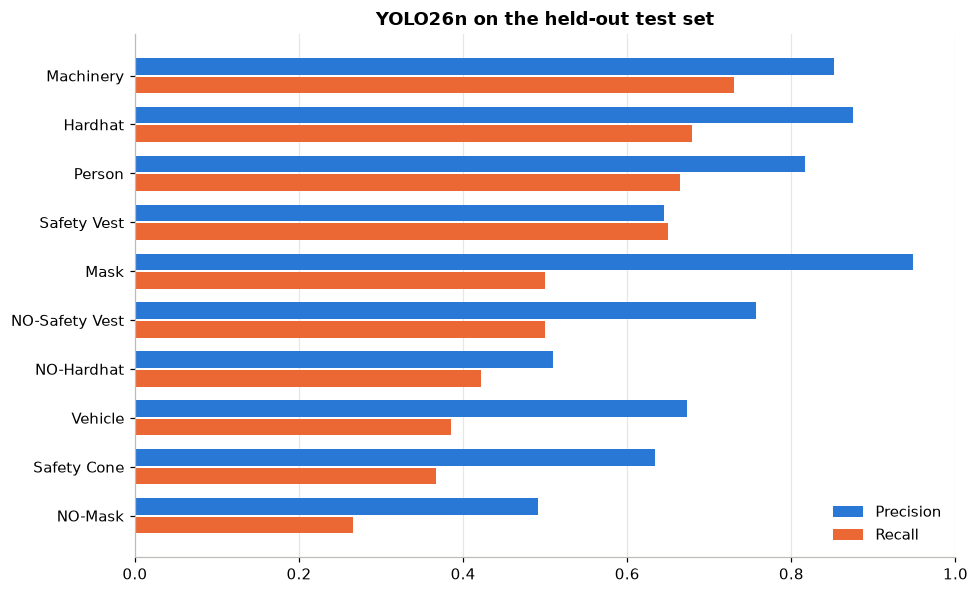

{'precision': 0.72, 'recall': 0.516, 'mAP50': 0.549, 'mAP50_95': 0.345, 'inference_ms': 56.787}


In [22]:
test_pc = pd.read_csv(C.METRICS_DIR / f"{FINAL}_test_per_class.csv").set_index("class").sort_values("recall")

fig, ax = plt.subplots(figsize=(9, 5.5))
y, h = np.arange(len(test_pc)), 0.38
ax.barh(y + h/2, test_pc["precision"], height=h - 0.04, color=BLUE, label="Precision")
ax.barh(y - h/2, test_pc["recall"], height=h - 0.04, color=ORANGE, label="Recall")
ax.set_yticks(y, test_pc.index)
ax.grid(axis="y", visible=False)
ax.set_xlim(0, 1)
ax.set_title("YOLO26n on the held-out test set")
ax.legend(loc="lower right")
save(fig, "08_test_per_class")

summary = json.load(open(C.METRICS_DIR / f"{FINAL}_test.json"))
print({k: round(v, 3) for k, v in summary.items()})

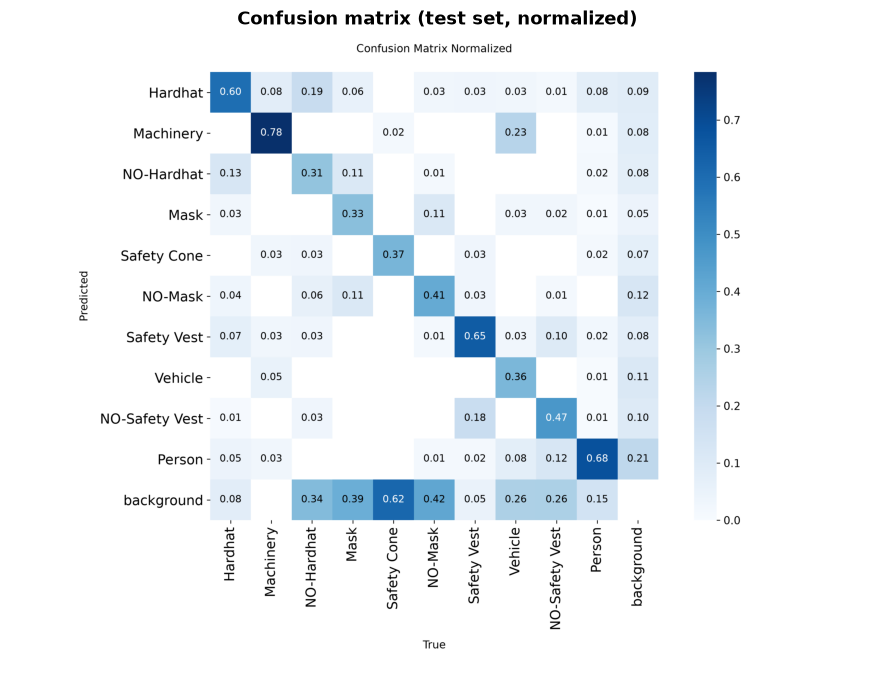

In [23]:
cm = RUNS / f"{FINAL}_test" / "confusion_matrix_normalized.png"
plt.figure(figsize=(10, 8)); plt.imshow(plt.imread(cm)); plt.axis("off")
plt.title("Confusion matrix (test set, normalized)"); plt.show()

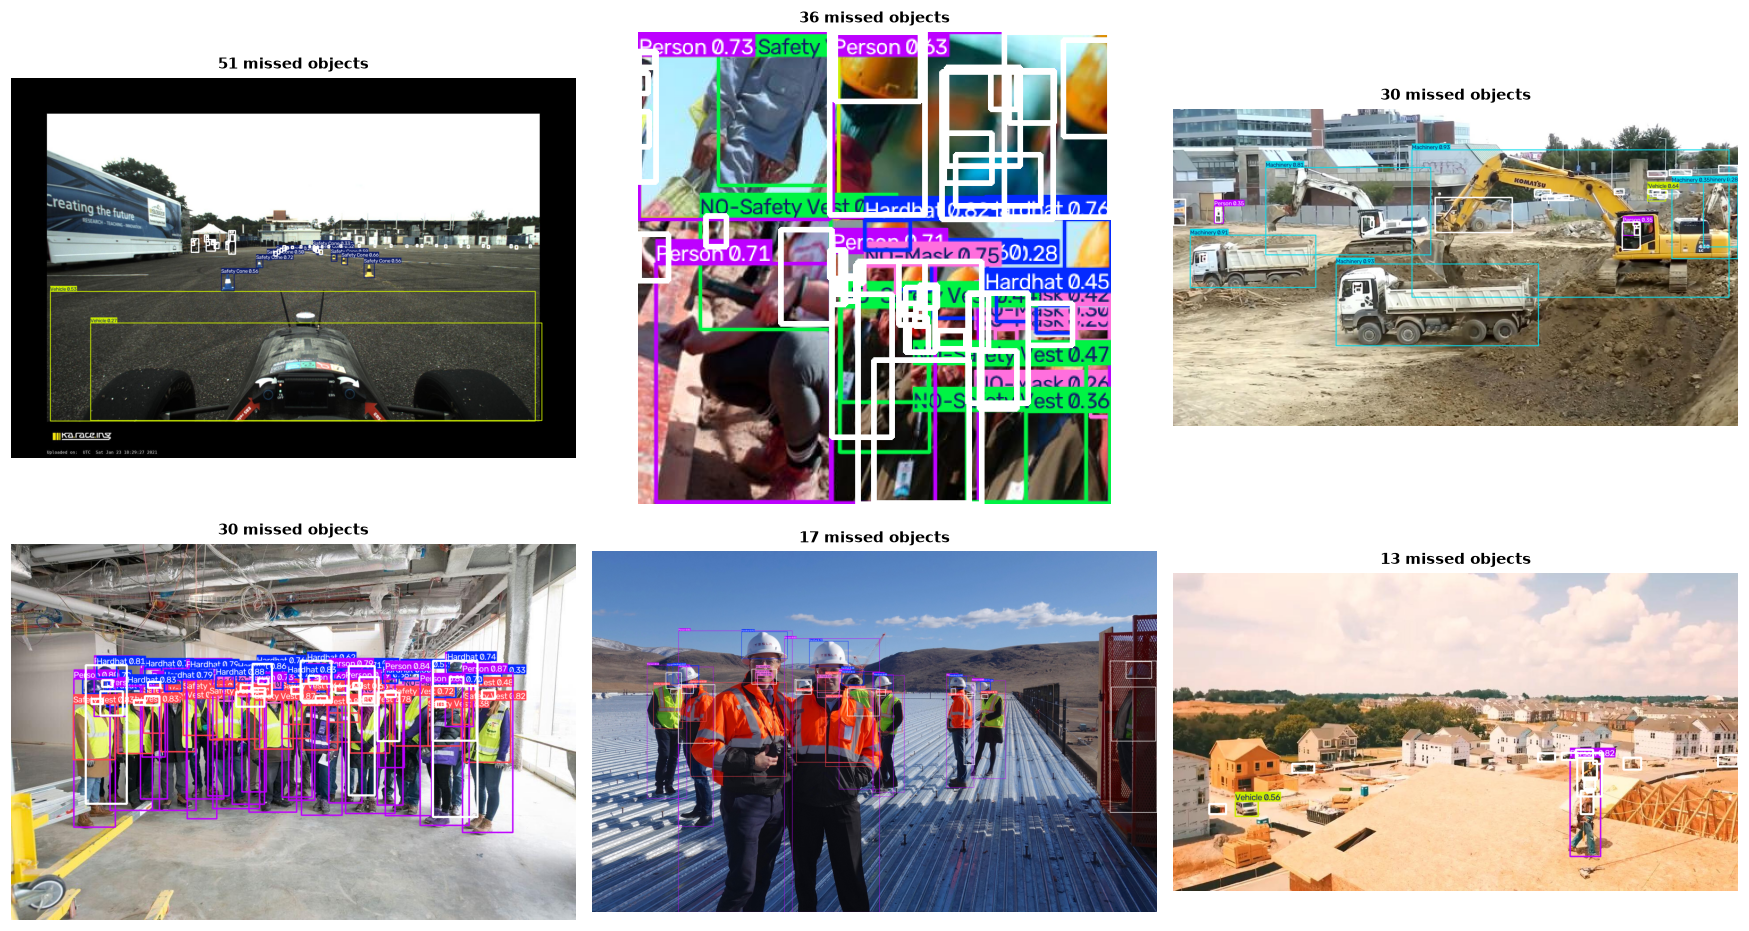

In [24]:
misses = (test_gts.assign(missed=~test_gts["found"])
          .groupby("image")["missed"].sum().sort_values(ascending=False).head(6))

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, (name, n) in zip(axes.flat, misses.items()):
    res = final_model.predict(str(C.PROCESSED_DIR / "test" / "images" / name), conf=0.25, verbose=False)[0]
    img = res.plot(line_width=2)
    for _, row in test_gts[(test_gts["image"] == name) & (~test_gts["found"])].iterrows():
        x1, y1, x2, y2 = row["box"].astype(int)
        cv2.rectangle(img, (x1, y1), (x2, y2), (255, 255, 255), 4)
    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    ax.set_title(f"{n} missed objects", fontsize=10)
    ax.axis("off")
save(fig, "09_error_gallery")